# Plotting Single-Bead Approximation fits from SASBDB benchmark outputs

This notebook collects and visualizes single-bead approximation (SBA) fits generated for SASBDB benchmark entries. It compares fitted scattering curves from different bead models, prepares selected publication-style panels, checks residuals, and summarizes chi-squared statistics for grid and Martini fits.

The plotting code assumes that the benchmark cache lives at `../../sasbdb_bench/cache` and that each SASBDB entry has CSV files such as `sba_fit_grid.csv` and `sba_fit_martini.csv`.

## Imports

Load numerical, plotting, filesystem, and tabular-data utilities used throughout the notebook.

In [1]:
# Core scientific Python imports used by all plotting and summary cells.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math
import pandas as pd

## Plot all Martini SBA fits

Find every `sba_fit_martini.csv` file in the cache, read the numeric columns, and draw the experimental intensity columns together with the fitted Martini intensity `i_fit`. The result is saved as a multi-panel PDF for a quick benchmark-wide inspection.

Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')


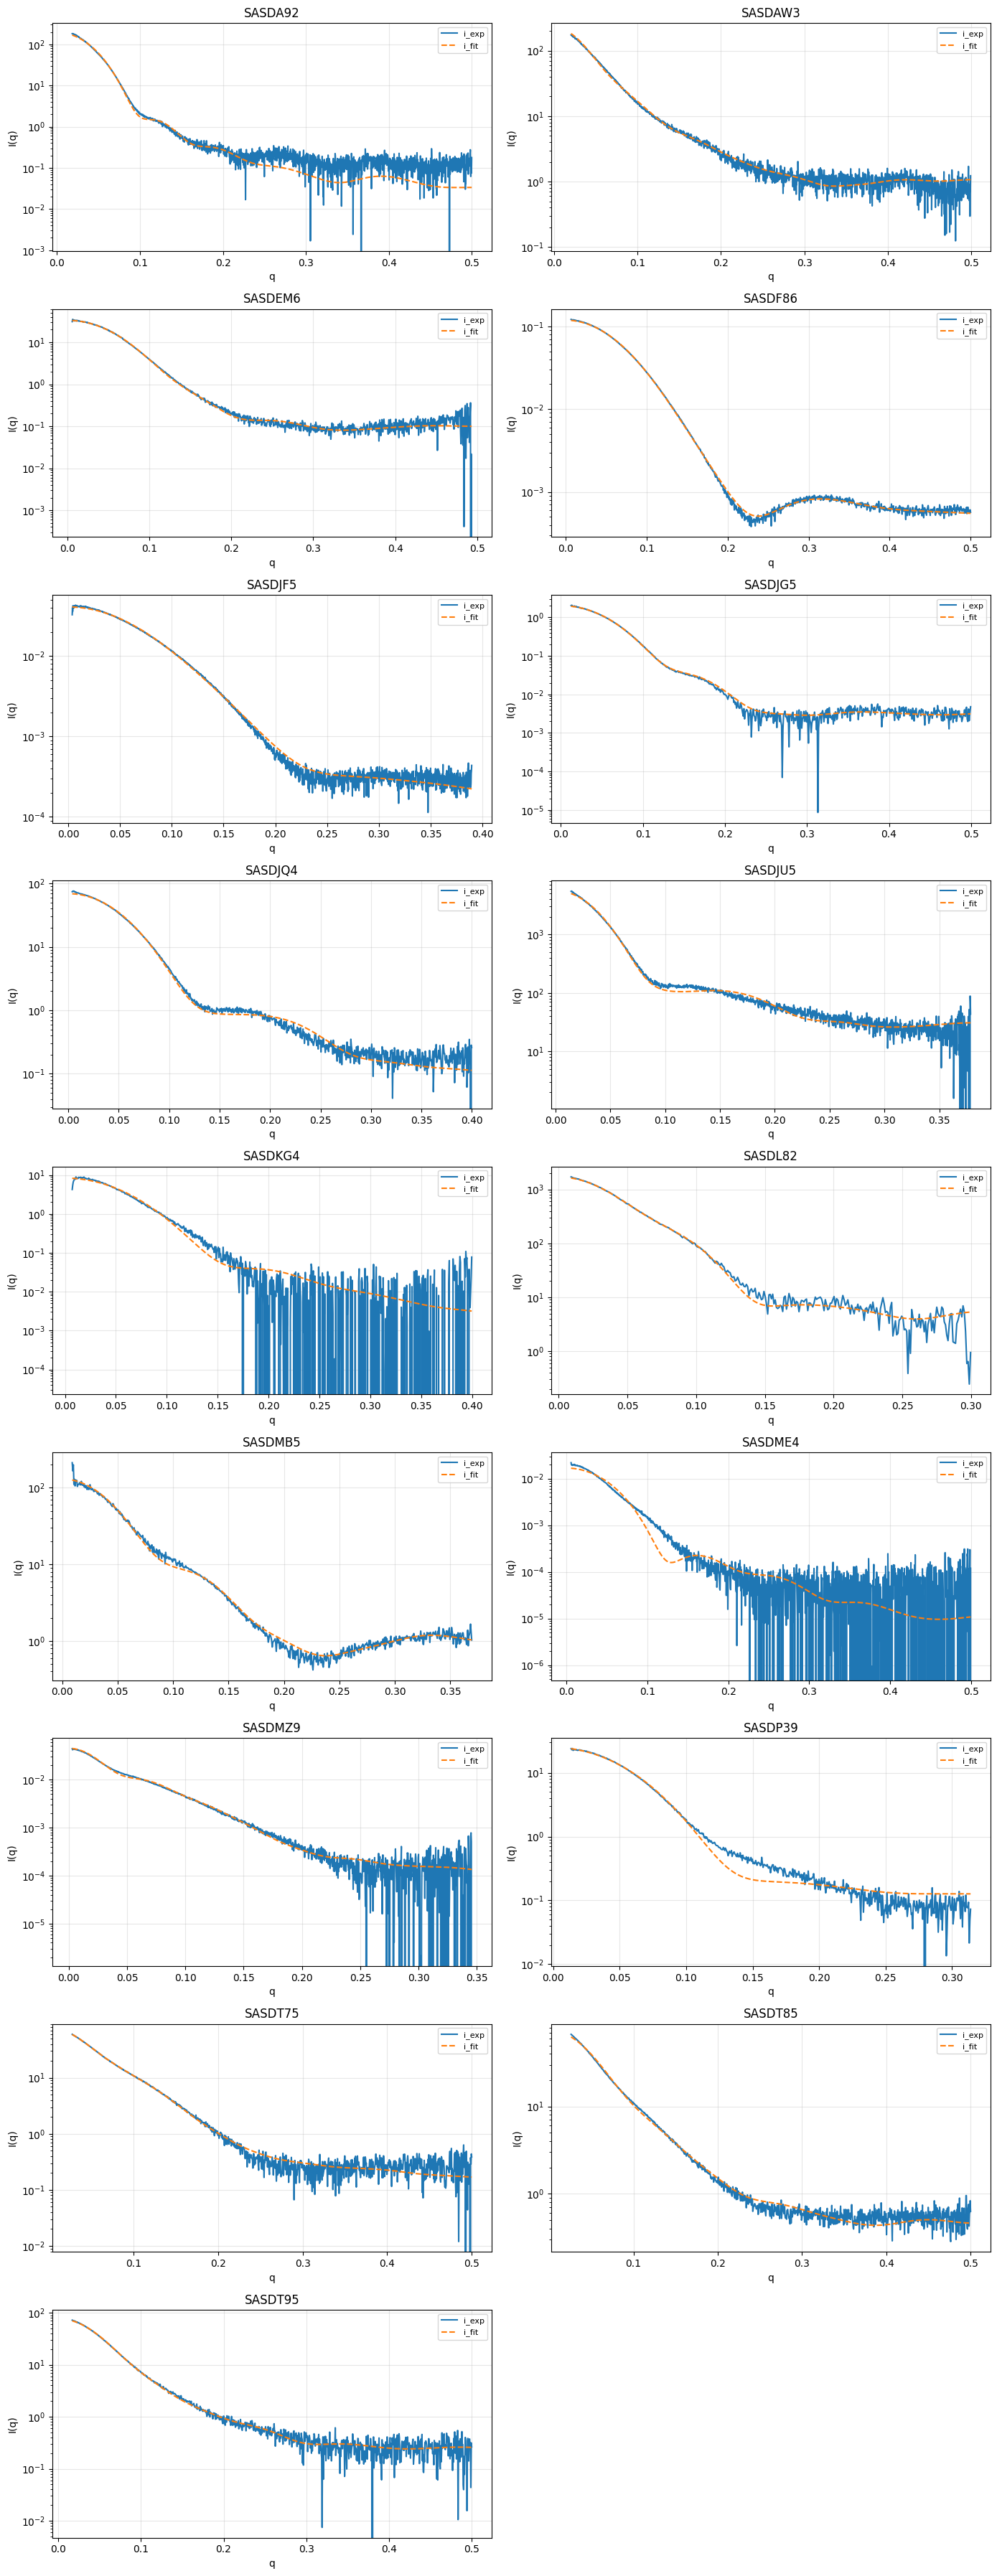

In [ ]:
base_dir = Path("../../sasbdb_bench/cache")

# Collect one Martini SBA fit file per benchmark entry.
csv_files = sorted(base_dir.glob("*/sba_fit_martini.csv"))

if not csv_files:
    raise FileNotFoundError(f"No matching files found under: {base_dir.resolve()}")

# Build a two-column grid large enough for every available fit file.
n = len(csv_files)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
axes = axes.ravel()

for ax, csv_path in zip(axes, csv_files):
    df = pd.read_csv(csv_path)
    num_df = df.select_dtypes(include=[np.number])
    print(num_df.columns)

    # Skip files that do not contain enough numeric data for an x/y plot.
    if num_df.shape[1] < 2:
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Not enough numeric columns to plot", ha="center", va="center")
        ax.axis("off")
        continue

    x = num_df.iloc[:, 0]

    # Plot each experimental intensity column, then overlay the fitted curve.
    for col in num_df.columns[1:-2]:  # Exclude last two columns, typically i_fit and sigma.
        ax.plot(x, num_df[col], label=col)
    ax.plot(x, num_df["i_fit"], label="i_fit", linestyle="--")

    ax.set_title(csv_path.parent.name)
    ax.set_xlabel(num_df.columns[0])
    ax.set_ylabel("I(q)")
    ax.grid(True, alpha=0.3)
    ax.set_yscale("log")
    ax.legend(fontsize=8)

# Hide unused subplot slots when the number of files is odd.
for ax in axes[len(csv_files):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(base_dir / "sba_fits_grid.pdf")
plt.show()

## Compare Amino acid bead model and Martini bead model fits

Select a small set of benchmark entries by index and plot experimental curves against both fitted models. The amino-acid bead fit comes from `sba_fit_grid.csv`, while the Martini bead fit comes from `sba_fit_martini.csv`. Panel labels are added for figure assembly.

4
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')


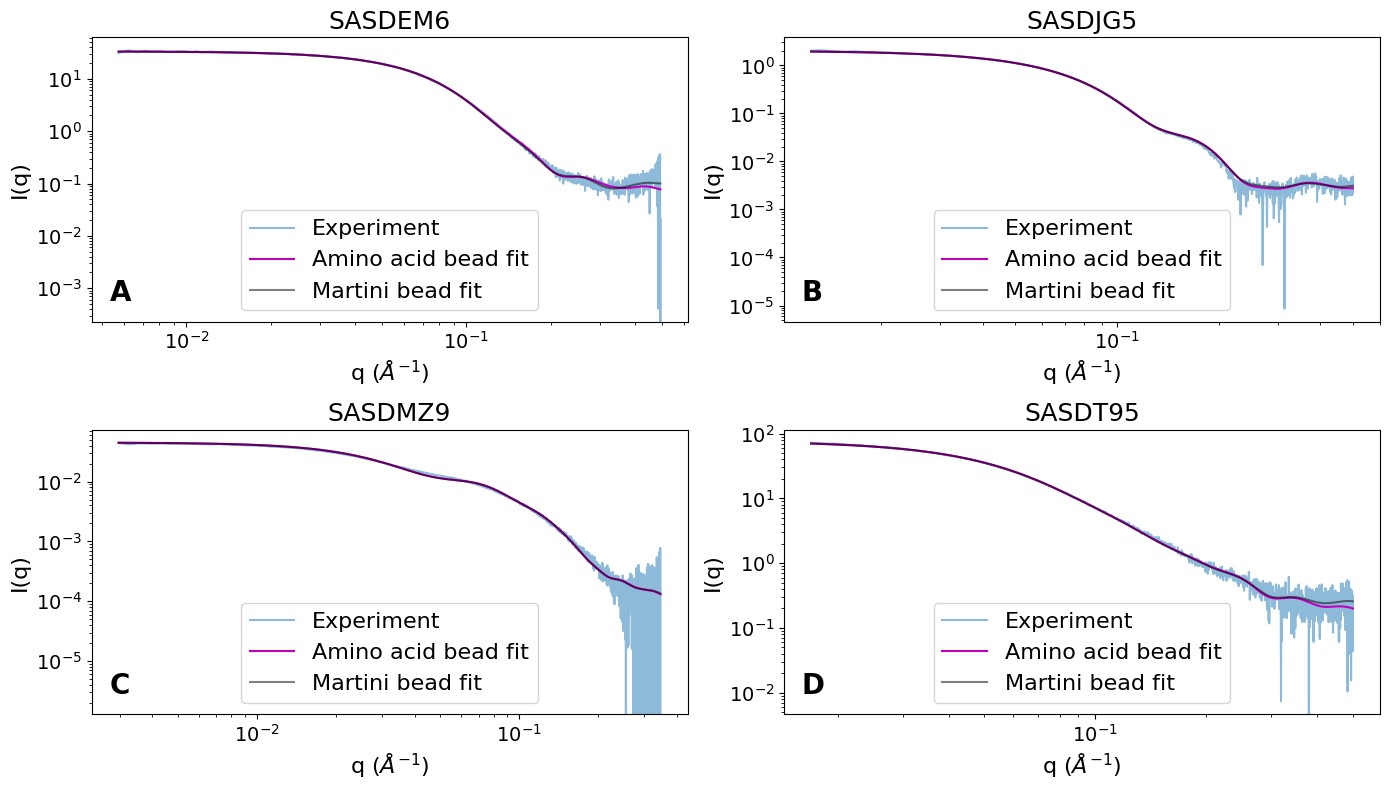

In [12]:
base_dir = Path("../../sasbdb_bench/cache")

# Load the two fit types in the same sorted order so index-based selections align.
csv_files = sorted(base_dir.glob("*/sba_fit_grid.csv"))
csv_files_martini = sorted(base_dir.glob("*/sba_fit_martini.csv"))

if not csv_files:
    raise FileNotFoundError(f"No matching files found under: {base_dir.resolve()}")

# Choose representative entries for the comparison figure.
selected_indices = [2, 5, 12, -1]
csv_files = [csv_files[i] for i in selected_indices]
csv_files_martini = [csv_files_martini[i] for i in selected_indices]

n = len(csv_files)
print(n)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
axes = axes.ravel()

for ax, csv_path, csv_path_martini in zip(axes, csv_files, csv_files_martini):
    df = pd.read_csv(csv_path)
    df_martini = pd.read_csv(csv_path_martini)
    num_df = df.select_dtypes(include=[np.number])
    num_df_martini = df_martini.select_dtypes(include=[np.number])
    print(num_df.columns)
    print(num_df_martini.columns)

    if num_df.shape[1] < 2:
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Not enough numeric columns to plot", ha="center", va="center")
        ax.axis("off")
        continue

    x = num_df.iloc[:, 0]

    # Draw all experimental intensity columns before adding model fits.
    for col in num_df.columns[1:-2]:  # Exclude last two columns, typically i_fit and sigma.
        ax.plot(x, num_df[col], label="Experiment", alpha=0.5)

    ax.plot(x, num_df["i_fit"], label="Amino acid bead fit", linestyle="-", color="m")
    ax.plot(x, num_df_martini["i_fit"], label="Martini bead fit", linestyle="-", color="k", alpha=0.5)

    ax.set_title(csv_path.parent.name, fontsize=18)
    ax.set_xlabel(r"q ($\AA^{-1}$)", fontsize=16)
    ax.set_ylabel("I(q)", fontsize=16)
    # ax.grid(True, alpha=0.3)
    ax.set_yscale("log")
    ax.set_xscale("log")
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.legend(fontsize=16, loc="lower center")

for ax in axes[len(csv_files):]:
    ax.axis("off")

# Add stable panel labels for downstream figure references.
panel_labels = ["A", "B", "C", "D"]
for i, ax in enumerate(axes[:len(csv_files)]):
    label = panel_labels[i] if i < len(panel_labels) else chr(ord("A") + i)
    ax.text(
        0.03,
        0.05,
        label,
        transform=ax.transAxes,
        fontsize=20,
        fontweight="bold",
        ha="left",
        va="bottom",
    )

plt.tight_layout()
plt.savefig(base_dir / "sba_fits_grid.pdf")
plt.show()

## Prepare an experiment-only panel

Build a one-panel plot for a selected entry using only the experimental intensity data. The cell writes a temporary CSV copy where `i_fit` is set to `NaN`, so the later plotting loop can reuse the same column-handling logic without drawing a fitted curve.

Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')
Index(['q', 'i_exp', 'i_fit', 'sigma'], dtype='object')


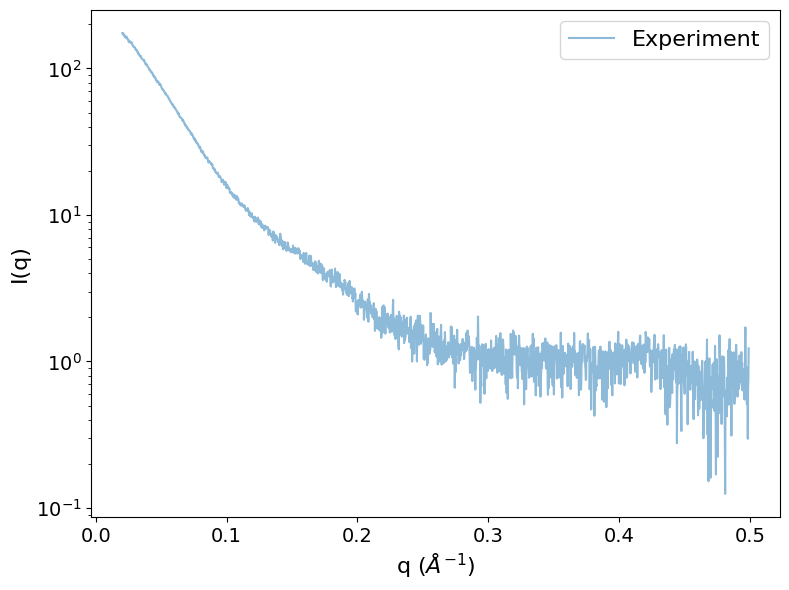

In [4]:
base_dir = Path("../../sasbdb_bench/cache")

csv_files = sorted(base_dir.glob("*/sba_fit_grid.csv"))

# Select the benchmark entry to show without fitted model overlays.
selected_indices = [1]
csv_files = [csv_files[i] for i in selected_indices]

csv_files_martini = sorted(base_dir.glob("*/sba_fit_martini.csv"))
csv_files_martini = [csv_files_martini[i] for i in selected_indices]

# Create temporary copies with i_fit removed so only experimental curves are plotted.
exp_only_files = []
for csv_path in csv_files:
    tmp_df = pd.read_csv(csv_path)
    if "i_fit" in tmp_df.columns:
        tmp_df["i_fit"] = np.nan
    tmp_path = base_dir / f"{csv_path.parent.name}_exp_only.csv"
    tmp_df.to_csv(tmp_path, index=False)
    exp_only_files.append(tmp_path)

csv_files = exp_only_files

nrows, ncols = 1, 1
fig, axes = plt.subplots(nrows, ncols, figsize=(8, 6), squeeze=False)
axes = axes.ravel()

for ax, csv_path, csv_path_martini in zip(axes, csv_files, csv_files_martini):
    df = pd.read_csv(csv_path)
    df_martini = pd.read_csv(csv_path_martini)
    num_df = df.select_dtypes(include=[np.number])
    num_df_martini = df_martini.select_dtypes(include=[np.number])
    print(num_df.columns)
    print(num_df_martini.columns)

    if num_df.shape[1] < 2:
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Not enough numeric columns to plot", ha="center", va="center")
        ax.axis("off")
        continue

    x = num_df.iloc[:, 0]

    # Plot experimental columns only. Fit overlays can be restored by uncommenting below.
    for col in num_df.columns[1:-2]:  # Exclude last two columns, typically i_fit and sigma.
        ax.plot(x, num_df[col], label="Experiment", alpha=0.5)
    # ax.plot(x, num_df_martini["i_fit"], label="Martini bead fit", linestyle="-", color="m")
    # ax.plot(x, num_df["i_fit"], label="Amino acid bead fit", linestyle="-", color="m")

    ax.set_xlabel(r"q ($\AA^{-1}$)", fontsize=16)
    ax.set_ylabel("I(q)", fontsize=16)
    # ax.grid(True, alpha=0.3)
    ax.set_yscale("log")
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.legend(fontsize=16)

for ax in axes[len(csv_files):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(base_dir / "sba_fits_grid_1.pdf")
plt.show()

## Plot residuals

Compute residuals as `i_exp - i_fit` for the currently selected files and plot them against `q`. This is useful for spotting systematic deviations that are harder to see on logarithmic intensity plots.

Note: if the previous experiment-only cell has replaced `i_fit` with `NaN`, this residual plot will also contain `NaN` residuals for those temporary files.

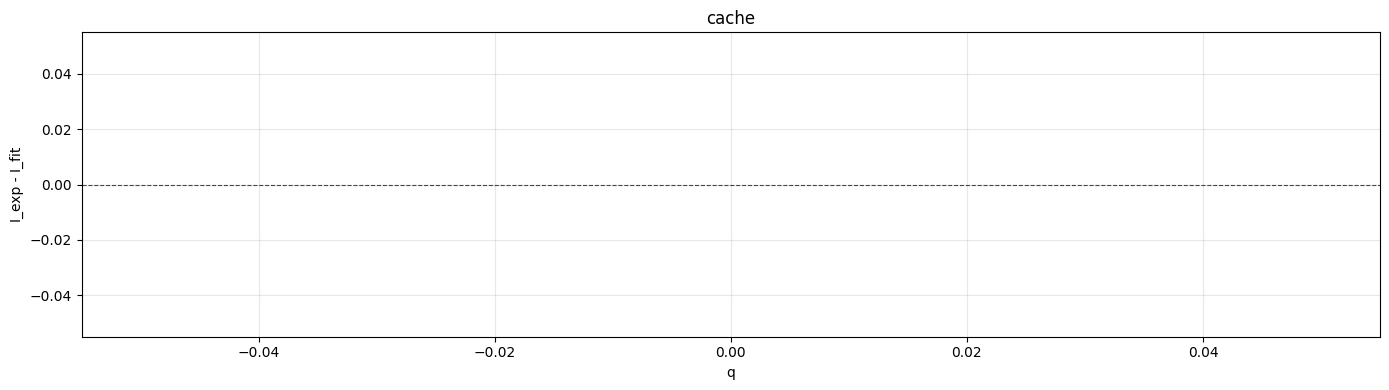

In [5]:
# Reuse nrows/ncols and csv_files from the previous selection cell.
fig_res, axes_res = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
axes_res = axes_res.ravel()

for ax, csv_path in zip(axes_res, csv_files):
    tmp_df = pd.read_csv(csv_path)
    num_tmp = tmp_df.select_dtypes(include=[np.number])

    # Residuals require explicit q, experimental intensity, and fitted intensity columns.
    if not {"q", "i_exp", "i_fit"}.issubset(num_tmp.columns):
        ax.set_title(csv_path.parent.name)
        ax.text(0.5, 0.5, "Missing q/i_exp/i_fit columns", ha="center", va="center")
        ax.axis("off")
        continue

    residual = num_tmp["i_exp"] - num_tmp["i_fit"]

    ax.plot(num_tmp["q"], residual, lw=1)
    ax.axhline(0, color="black", ls="--", lw=0.8, alpha=0.7)
    ax.set_title(csv_path.parent.name)
    ax.set_xlabel("q")
    ax.set_ylabel("I_exp - I_fit")
    ax.grid(True, alpha=0.3)
    # ax.set_yscale("log")
    # ax.set_xscale("log")

for ax in axes_res[len(csv_files):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(base_dir / "sba_residuals_grid.pdf")
plt.show()

## Load chi-squared summaries

Read the benchmark summary CSV files and compare the mean `chi2_per_point` values for amino-acid grid fits and Martini fits. One Martini row is dropped to align the two summary tables before comparison.

In [160]:
summary_path = base_dir / "sba_summary_grid.csv"
summary_path_martini = base_dir / "sba_summary_martini.csv"

if not summary_path.exists():
    raise FileNotFoundError(f"File not found: {summary_path.resolve()}")

# Read the leading summary columns, including sid and chi2_per_point.
summary_df = pd.read_csv(summary_path, usecols=range(4))
summary_df_martini = pd.read_csv(summary_path_martini, usecols=range(4))
# summary_df = pd.read_csv(summary_path)

# Drop the Martini outlier/mismatched row so the two tables align by row.
summary_df_martini = summary_df_martini.drop(index=11)

print(np.mean(summary_df["chi2_per_point"]))
print(np.mean(summary_df_martini["chi2_per_point"]))

6.666302040833983
6.8857041521516145


## Export a chi-squared comparison table

Assemble the per-entry chi-squared values into a compact table, then print both a LaTeX version for manuscripts and a plain-text version for notebook inspection.

In [168]:
# Keep only the identifier and chi-squared values needed for the comparison table.
comparison_df = pd.DataFrame(
    {
        "sid": summary_df["sid"],
        "chi2_grid": summary_df["chi2_per_point"],
        "chi2_martini": summary_df_martini["chi2_per_point"],
    }
)

# Optional derived metrics for follow-up analysis.
# comparison_df["difference"] = comparison_df["chi2_grid"] - comparison_df["chi2_martini"]
# comparison_df["percent_change"] = (
#     comparison_df["difference"] / comparison_df["chi2_grid"] * 100
# ).round(2)

latex_table = comparison_df.to_latex(
    index=False,
    float_format="%.2f",
    na_rep="--",
    caption="Comparison of chi2 per point (Grid vs Martini)",
    label="tab:chi2_comparison",
)

print(latex_table)
print(comparison_df.to_string(index=False))
# summary_df["sid"]
# summary_df["chi2_per_point"]
# summary_df_martini["chi2_per_point"]

\begin{table}
\caption{Comparison of chi2 per point (Grid vs Martini)}
\label{tab:chi2_comparison}
\begin{tabular}{lrr}
\toprule
sid & chi2_grid & chi2_martini \\
\midrule
SASDA92 & 12.08 & 11.97 \\
SASDAW3 & 7.49 & 8.00 \\
SASDEM6 & 4.85 & 5.84 \\
SASDF86 & 12.21 & 5.54 \\
SASDJF5 & 5.51 & 5.70 \\
SASDJG5 & 3.59 & 3.20 \\
SASDJQ4 & 10.41 & 10.10 \\
SASDJU5 & 3.71 & 4.15 \\
SASDKG4 & 5.39 & 5.62 \\
SASDL82 & 2.65 & 2.52 \\
SASDMB5 & 6.35 & 5.89 \\
SASDME4 & 1.41 & -- \\
SASDMZ9 & 14.65 & 14.62 \\
SASDP39 & 2.07 & 8.89 \\
SASDT75 & 1.78 & 1.65 \\
SASDT85 & 17.08 & 14.52 \\
SASDT95 & 2.11 & 1.96 \\
\bottomrule
\end{tabular}
\end{table}

    sid  chi2_grid  chi2_martini
SASDA92  12.079575     11.965604
SASDAW3   7.488310      7.996393
SASDEM6   4.854856      5.844511
SASDF86  12.207094      5.537906
SASDJF5   5.508333      5.696015
SASDJG5   3.590875      3.203928
SASDJQ4  10.406385     10.100352
SASDJU5   3.705424      4.149262
SASDKG4   5.392569      5.618287
SASDL82   2.652590      2.5